# Yash's inverse PINN for lynx and hare dynamics

**All observations in this notebook are synthetic.** Year labels reproduce the planned
1900–1915 training and 1916–1920 testing split. They are not historical pelt counts.

We implement an inverse PINN, recover known parameters under controlled noise, then
freeze those parameters and use an ODE solver for held-out predictions. The notebook
documents Yash's part and provisional integration aids, not the entire group's work.

<div style="border-left:4px solid #197278;padding-left:12px">Read the mathematical
explanations before running each code block. The default experiment driver reuses
completed runs with a matching configuration; fresh training requires a new result directory.</div>

## Setup and reproducible configuration

Use the environment in the README. Seeds, bounds, loss weights and solver tolerances
are explicit. This notebook locates the repository from either its root or the notebook
directory; it contains no machine-specific absolute paths.

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd().resolve()
if not (ROOT / 'configs/synthetic.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'configs/synthetic.json').exists(), 'Run from the repository or notebooks folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import torch
from IPython.display import display, Markdown, Image
CONFIG = json.loads((ROOT / 'configs/synthetic.json').read_text())
display(Markdown('**Configuration**'))
print(json.dumps(CONFIG, indent=2))

**Configuration**

{
  "description": "SYNTHETIC demonstration only; years are labels, not historical measurements",
  "truth": {
    "r": 1.0,
    "K": 60.0,
    "a": 2.0,
    "b": 20.0,
    "e": 0.6,
    "m": 0.5
  },
  "initial_state": [
    35.0,
    9.0
  ],
  "start_year": 1900,
  "train_end_year": 1915,
  "test_end_year": 1920,
  "data_seed": 314,
  "noise_fraction": 0.03,
  "trainable": [
    "r",
    "a",
    "m"
  ],
  "initial_guess": {
    "r": 0.7,
    "K": 60.0,
    "a": 1.4,
    "b": 20.0,
    "e": 0.6,
    "m": 0.35
  },
  "bounds": {
    "r": [
      0.2,
      2.5
    ],
    "K": [
      25.0,
      150.0
    ],
    "a": [
      0.3,
      4.0
    ],
    "b": [
      5.0,
      60.0
    ],
    "e": [
      0.1,
      1.5
    ],
    "m": [
      0.1,
      1.2
    ]
  },
  "solver": {
    "rtol": 1e-08,
    "atol": 1e-10,
    "max_step": 0.1
  },
  "training": {
    "width": 48,
    "depth": 3,
    "collocation_points": 161,
    "warmup_steps": 500,
    "adam_steps": 5000,
    "lbfgs_ste

## Complete program 1 Model and ODE solver

The following cell defines both NumPy and Torch versions of the equations and the common RK45 solver. The solver checks inputs, integration success and nonnegative states.

This code cell is generated from `src/lynx_hare/model.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [2]:
"""Shared dimensional model and RK45 solver, provisional until team agreement."""
from dataclasses import dataclass, asdict
import numpy as np
from scipy.integrate import solve_ivp

NAMES = ("r", "K", "a", "b", "e", "m")


@dataclass(frozen=True)
class Parameters:
    r: float
    K: float
    a: float
    b: float
    e: float
    m: float

    def __post_init__(self):
        if not all(np.isfinite(v) and v > 0 for v in asdict(self).values()):
            raise ValueError("Every model parameter must be finite and positive")

    def to_dict(self):
        return asdict(self)


def rhs(t, state, p):
    """H' = rH(1-H/K)-aHP/(b+H); P' = eaHP/(b+H)-mP."""
    H, P = state
    consumption = p.a * H * P / (p.b + H)
    return np.array([p.r * H * (1 - H / p.K) - consumption,
                     p.e * consumption - p.m * P])


def rhs_torch(state, p):
    """Same equations, batch shape (N, 2), preserving the autograd graph."""
    import torch
    H, P = state[:, :1], state[:, 1:]
    consumption = p["a"] * H * P / (p["b"] + H)
    return torch.cat((p["r"] * H * (1 - H / p["K"]) - consumption,
                      p["e"] * consumption - p["m"] * P), dim=1)


def solve(times, initial_state, p, rtol=1e-8, atol=1e-10, max_step=0.1):
    """State at strictly increasing times; initial_state belongs to times[0]."""
    times = np.asarray(times, dtype=float)
    y0 = np.asarray(initial_state, dtype=float)
    if times.ndim != 1 or times.size == 0 or not np.isfinite(times).all():
        raise ValueError("times must be a nonempty finite 1D array")
    if np.any(np.diff(times) <= 0) or y0.shape != (2,) or not np.isfinite(y0).all() or np.any(y0 < 0):
        raise ValueError("times must increase; initial_state must contain two nonnegative values")
    if times.size == 1:
        return y0[None, :].copy()
    result = solve_ivp(lambda t, y: rhs(t, y, p), (times[0], times[-1]), y0,
                       t_eval=times, method="RK45", rtol=rtol, atol=atol, max_step=max_step)
    if not result.success or result.y.shape[1] != len(times):
        raise RuntimeError(f"ODE integration failed: {result.message}")
    states = result.y.T
    if not np.isfinite(states).all() or np.min(states) < -100 * atol:
        raise RuntimeError("ODE returned invalid or negative states")
    return states

## Complete program 2 Data and synthetic observations

This cell validates the training-data contract, computes training-only scales, and generates controlled-noise observations. The first observation is exact in this synthetic experiment.

This code cell is generated from `src/lynx_hare/data.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [3]:
"""Validated training contract and independently generated synthetic observations."""
from dataclasses import dataclass
from pathlib import Path
import csv
import numpy as np


@dataclass
class TrainingData:
    years: np.ndarray
    observations: np.ndarray
    time_origin: float

    def __post_init__(self):
        self.years = np.asarray(self.years, dtype=float)
        self.observations = np.asarray(self.observations, dtype=float)
        if (self.years.ndim != 1 or len(self.years) < 2
                or self.observations.shape != (len(self.years), 2)
                or not np.isfinite(self.years).all()
                or not np.isfinite(self.observations).all()
                or np.any(np.diff(self.years) <= 0)
                or np.any(self.observations <= 0)
                or not np.isfinite(self.time_origin)
                or self.years[0] != self.time_origin):
            raise ValueError("Training data require increasing years and positive finite Hare/Lynx observations, starting at time_origin")

    @property
    def times(self):
        return self.years - self.time_origin

    @property
    def scale(self):
        # This method has no access to test observations or generating parameters.
        return self.observations.max(axis=0)

    @property
    def initial_state(self):
        return self.observations[0].copy()


def write_csv(path, columns, values):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(columns)
        writer.writerows(values)


def read_training(path, time_origin=1900, train_end=1915):
    with Path(path).open(newline="", encoding="utf-8-sig") as f:
        rows = list(csv.DictReader(f))
    values = np.array([[float(r[k]) for k in ("Year", "Hare", "Lynx")] for r in rows])
    values = values[values[:, 0] <= train_end]
    return TrainingData(values[:, 0], values[:, 1:], time_origin)


def synthetic(config, times, noise_fraction=None, seed=None):
    """Noise is multiplicative Gaussian with exact controlled initial condition.

    In this synthetic experiment the initial state is treated as measured exactly.
    This is an explicit experimental assumption, not a claim about pelt data.
    """
    noise = config["noise_fraction"] if noise_fraction is None else noise_fraction
    if noise < 0:
        raise ValueError("noise_fraction cannot be negative")
    states = solve(times, config["initial_state"], Parameters(**config["truth"]), **config["solver"])
    rng = np.random.default_rng(config["data_seed"] if seed is None else seed)
    observed = states * (1 + noise * rng.normal(size=states.shape))
    observed = np.maximum(observed, 1e-8)
    observed[0] = states[0]
    return states, observed

## Complete program 3 Inverse PINN and training

The full network, bounded unknown parameters, automatic residuals, loss terms, Adam warmup/joint optimization, L-BFGS refinement and checkpoint selection appear below. Training receives no held-out observations or generating truth.

This code cell is generated from `src/lynx_hare/pinn.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [4]:
"""Inverse PINN trained only on a TrainingData object and fixed configuration."""
import copy
import random
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

DTYPE = torch.float64


class InversePINN(nn.Module):
    def __init__(self, duration, scale, guess, bounds, trainable, width=48, depth=3):
        super().__init__()
        if duration <= 0 or not set(trainable).issubset(NAMES) or len(set(trainable)) != len(trainable):
            raise ValueError("Invalid duration or trainable parameter names")
        self.duration = float(duration)
        self.register_buffer("scale", torch.as_tensor(scale, dtype=DTYPE))
        self.fixed = {k: float(v) for k, v in guess.items() if k not in trainable}
        self.bounds = bounds
        self.raw = nn.ParameterDict()
        for k in trainable:
            lo, hi = bounds[k]
            if not 0 < lo < guess[k] < hi:
                raise ValueError(f"Initial guess for {k} must lie strictly within positive bounds")
            q = (guess[k] - lo) / (hi - lo)
            self.raw[k] = nn.Parameter(torch.tensor(np.log(q / (1 - q)), dtype=DTYPE))
        layers = [nn.Linear(1, width), nn.Tanh()]
        for _ in range(depth - 1):
            layers.extend((nn.Linear(width, width), nn.Tanh()))
        layers.append(nn.Linear(width, 2))
        self.network = nn.Sequential(*layers).to(dtype=DTYPE)
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def parameter_values(self):
        values = dict(self.fixed)
        for k, raw in self.raw.items():
            lo, hi = self.bounds[k]
            values[k] = lo + (hi - lo) * torch.sigmoid(raw)
        return values

    def inferred(self):
        return Parameters(**{k: float(v.detach()) if isinstance(v, torch.Tensor) else float(v)
                             for k, v in self.parameter_values().items()})

    def forward(self, times):
        # The network is defined on scaled time [-1, 1]. Output positivity is strict.
        return F.softplus(self.network(2 * times / self.duration - 1)) + 1e-10

    def residuals(self, times):
        times = times.detach().clone().requires_grad_(True)
        normalized = self(times)
        derivatives = torch.cat([
            torch.autograd.grad(normalized[:, j:j+1], times,
                                torch.ones_like(normalized[:, j:j+1]), create_graph=True)[0]
            for j in range(2)], dim=1)
        return derivatives - rhs_torch(normalized * self.scale, self.parameter_values()) / self.scale


def loss_parts(model, times, observations, collocation, initial):
    data = ((model(times) - observations / model.scale) ** 2).mean()
    residual = model.residuals(collocation)
    physics_hare = residual[:, 0].square().mean()
    physics_lynx = residual[:, 1].square().mean()
    ic = ((model(torch.zeros((1, 1), dtype=DTYPE)) - initial / model.scale) ** 2).mean()
    return {"data": data, "physics": (physics_hare + physics_lynx) / 2,
            "physics_hare": physics_hare, "physics_lynx": physics_lynx, "ic": ic}


def fit_pinn(data, config, seed, training_overrides=None, initial_factor=1.0, trainable=None):
    """No truth, held-out observations, or held-out metrics enter optimization."""
    settings = {**config["training"], **(training_overrides or {})}
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(settings["threads"])
    torch.use_deterministic_algorithms(True)
    names = config["trainable"] if trainable is None else trainable
    guess = dict(config["initial_guess"])
    for k in names:
        lo, hi = config["bounds"][k]
        guess[k] = float(np.clip(guess[k] * initial_factor, lo + 1e-4, hi - 1e-4))
    model = InversePINN(data.times[-1], data.scale, guess, config["bounds"], names,
                        settings["width"], settings["depth"])
    times = torch.as_tensor(data.times[:, None], dtype=DTYPE)
    observed = torch.as_tensor(data.observations, dtype=DTYPE)
    initial = torch.as_tensor(data.initial_state, dtype=DTYPE)
    collocation = torch.linspace(0, data.times[-1], settings["collocation_points"], dtype=DTYPE)[:, None]
    history, best_state = [], None
    best_loss, stale, best_iteration = float("inf"), 0, -1
    start = time.perf_counter()

    def total(parts):
        return (settings["data_weight"] * parts["data"] + settings["physics_weight"] * parts["physics"]
                + settings["ic_weight"] * parts["ic"])

    def record(stage, step):
        nonlocal best_state, best_loss, stale, best_iteration
        parts = loss_parts(model, times, observed, collocation, initial)
        score = float(total(parts).detach())
        if not np.isfinite(score):
            raise RuntimeError("Nonfinite PINN training objective")
        history.append({"stage": stage, "step": step, "total": score,
                        **{k: float(v.detach()) for k, v in parts.items()}})
        improved_materially = score < best_loss - settings["min_delta"]
        stale = 0 if improved_materially else stale + 1
        if score < best_loss:
            best_loss, best_state, best_iteration = score, copy.deepcopy(model.state_dict()), step
        return score

    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
    # Warmup fits states before physics is introduced. No parameters are inferred in warmup.
    for _ in range(settings["warmup_steps"]):
        optimizer.zero_grad()
        warm = ((model(times) - observed / model.scale) ** 2).mean()
        warm = warm + settings["ic_weight"] * ((model(times[:1]) - initial / model.scale) ** 2).mean()
        warm.backward()
        optimizer.step()
    record("joint_adam", 0)
    adam_stop = "maximum_steps"
    for step in range(1, settings["adam_steps"] + 1):
        optimizer.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite PINN loss")
        objective.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip"])
        optimizer.step()
        if step % settings["log_every"] == 0 or step == settings["adam_steps"]:
            record("joint_adam", step)
            if stale >= settings["patience"]:
                adam_stop = "training_plateau"
                break
    model.load_state_dict(best_state)
    closure_evaluations = 0
    optimizer2 = torch.optim.LBFGS(model.parameters(), max_iter=settings["lbfgs_steps"],
                                  line_search_fn="strong_wolfe", tolerance_grad=1e-10,
                                  tolerance_change=1e-12, history_size=50)

    def closure():
        nonlocal closure_evaluations
        optimizer2.zero_grad()
        objective = total(loss_parts(model, times, observed, collocation, initial))
        if not torch.isfinite(objective):
            raise RuntimeError("Nonfinite L-BFGS loss")
        objective.backward()
        closure_evaluations += 1
        if closure_evaluations % 25 == 0:
            record("lbfgs", settings["adam_steps"] + closure_evaluations)
        return objective

    if settings["lbfgs_steps"]:
        optimizer2.step(closure)
        record("lbfgs_final", settings["adam_steps"] + closure_evaluations)
    model.load_state_dict(best_state)
    audit = {"seed": seed, "settings": settings, "trainable": names, "initial_guess": guess,
             "fixed": model.fixed, "scale": data.scale.tolist(), "train_years": data.years.tolist(),
             "training_objective": best_loss, "best_iteration": best_iteration,
             "adam_stop": adam_stop, "lbfgs_iterations": optimizer2.state.get(next(iter(model.parameters())), {}).get("n_iter", 0),
             "lbfgs_closure_evaluations": closure_evaluations,
             "elapsed_seconds": time.perf_counter() - start,
             "selection_rule": "minimum weighted training loss; held-out data never used"}
    return model, history, audit

## Complete program 4 Matching baseline and identifiability

Least squares fits the same unknowns with the shared solver, fixed constants, bounds and initial condition. Finite differences of log parameters provide a local sensitivity diagnostic.

This code cell is generated from `src/lynx_hare/baseline.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [5]:
"""Provisional least-squares benchmark, shared solver, bounds, fixed values and IC."""
import numpy as np
from scipy.optimize import least_squares


def fit_least_squares(data, config, multistart=6, seed=91):
    names = config["trainable"]
    lower = np.array([config["bounds"][k][0] for k in names])
    upper = np.array([config["bounds"][k][1] for k in names])
    base = np.array([config["initial_guess"][k] for k in names])
    rng = np.random.default_rng(seed)

    def parameters(x):
        return Parameters(**{**config["initial_guess"], **dict(zip(names, x))})

    def residual(x):
        try:
            predicted = solve(data.times, data.initial_state, parameters(x), **config["solver"])
            return ((predicted - data.observations) / data.scale).ravel()
        except RuntimeError:
            return np.full(data.observations.size, 1e6)

    candidates, logs = [], []
    for i in range(multistart):
        guess = base if i == 0 else rng.uniform(lower + 1e-5, upper - 1e-5)
        fit = least_squares(residual, guess, bounds=(lower, upper), max_nfev=500,
                             ftol=1e-10, xtol=1e-10, gtol=1e-10)
        candidates.append(fit)
        logs.append({"start": i, "initial_guess": guess.tolist(), "cost": float(fit.cost),
                     "success": bool(fit.success), "status": int(fit.status), "nfev": int(fit.nfev),
                     "message": fit.message})
    eligible = [f for f in candidates if f.success and np.isfinite(f.cost)]
    if not eligible:
        raise RuntimeError("No least-squares start converged")
    best = min(eligible, key=lambda f: f.cost)
    return parameters(best.x), logs


def sensitivity_spectrum(data, p, config, names):
    """Local scaled trajectory sensitivity w.r.t. log parameters, not a proof of identifiability."""
    columns = []
    eps = 1e-4
    for k in names:
        plus, minus = p.to_dict(), p.to_dict()
        plus[k] *= np.exp(eps)
        minus[k] *= np.exp(-eps)
        delta = (solve(data.times, data.initial_state, Parameters(**plus), **config["solver"])
                 - solve(data.times, data.initial_state, Parameters(**minus), **config["solver"]))
        columns.append((delta / (2 * eps) / data.scale).ravel())
    singular = np.linalg.svd(np.column_stack(columns), compute_uv=False)
    return {"names": list(names), "singular_values": singular.tolist(),
            "condition_number": float(singular[0] / singular[-1])}

## Complete program 5 Publication figures

These functions build every scientific figure from saved numerical evidence and export matching PNG, EPS and vector PDF formats. The PDF companions let PDF engines compile the EPS-referenced report without a system EPS converter.

This code cell is generated from `src/lynx_hare/figures.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [6]:
"""EPS and PNG figures; captions are in docs/figure_captions.md."""
import json
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter


def make_figures(root, output, truth, observations, summaries, scores):
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                         "savefig.dpi": 180, "ps.fonttype": 42, "pdf.fonttype": 42})
    figdir = output / "figures"
    figdir.mkdir(exist_ok=True)
    colors = ["#197278", "#C4532E", "#4E3F82"]

    def save(fig, name):
        fig.savefig(figdir / f"{name}.png", bbox_inches="tight", facecolor="white")
        fig.savefig(figdir / f"{name}.eps", bbox_inches="tight", facecolor="white")
        fig.savefig(figdir / f"{name}.pdf", bbox_inches="tight", facecolor="white")
        plt.close(fig)

    selected_id = json.loads((output / "selected_run.json").read_text())["run_id"]
    folder = output / "runs" / selected_id
    pinn = np.loadtxt(folder / "ode_dense.csv", delimiter=",", skiprows=1)
    network = np.loadtxt(folder / "network_train.csv", delimiter=",", skiprows=1)
    baseline = json.loads((output / "least_squares.json").read_text())["parameters"]
    config = json.loads((root / "configs/synthetic.json").read_text())
    grid = pinn[:, 0] - 1900
    base = solve(grid, observations[0], Parameters(**baseline), **config["solver"])
    exact = solve(grid, config["initial_state"], Parameters(**config["truth"]), **config["solver"])
    fig, axes = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True, layout="constrained")
    for j, ax in enumerate(axes):
        ax.axvspan(1915, 1920, color="#EEEEEE", label="Held-out period")
        ax.plot(grid + 1900, exact[:, j], color="black", lw=1.4, label="Synthetic latent truth")
        ax.scatter(np.arange(1900, 1916), observations[:16, j], s=21, color=colors[0], label="Training observations", zorder=4)
        ax.scatter(np.arange(1916, 1921), observations[16:, j], s=30, marker="x", color="black", label="Held-out observations", zorder=4)
        ax.plot(pinn[:, 0], pinn[:, j+1], color=colors[1], lw=1.6, label="PINN-derived ODE")
        ax.plot(grid + 1900, base[:, j], color=colors[2], ls="--", lw=1.5, label="Least-squares ODE")
        ax.set_ylabel(["Hare index", "Lynx index"][j])
        ax.grid(color="#E5E5E5", linewidth=0.6)
    axes[0].legend(ncol=3, fontsize=8, frameon=False)
    axes[0].set_title("Synthetic annual observations and frozen ODE forecasts")
    axes[-1].set_xlabel("Year label (synthetic data)")
    save(fig, "forecast_comparison")

    history = np.genfromtxt(folder / "training.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    for name, color in zip(("total", "data", "physics", "ic"), ("black", *colors)):
        ax.semilogy(history["step"], np.maximum(history[name], 1e-14), label=name, color=color)
    ax.set(xlabel="Joint Adam steps + L-BFGS closure evaluations", ylabel="Loss", title=f"Synthetic training losses ({selected_id})")
    ax.legend(frameon=False, ncol=4)
    ax.grid(color="#E5E5E5")
    save(fig, "training_losses")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    for j, ax in enumerate(axes):
        ax.plot(network[:, 0], network[:, j+1], color=colors[0], label="PINN state approximation")
        train_grid = pinn[pinn[:, 0] <= 1915]
        ax.plot(train_grid[:, 0], train_grid[:, j+1], color=colors[1], ls="--", label="ODE with inferred parameters")
        ax.scatter(np.arange(1900, 1916), observations[:16, j], color="black", s=15, label="Training observations")
        ax.set(xlabel="Synthetic year label", ylabel=["Hare index", "Lynx index"][j])
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle("Training consistency between network and ODE")
    save(fig, "network_ode_consistency")

    fig, axes = plt.subplots(1, 3, figsize=(10, 3.8), layout="constrained")
    for j, name in enumerate(config["trainable"]):
        ax = axes[j]
        for x, case in enumerate(("dense_clean", "dense_noisy", "annual_noisy")):
            values = [100 * abs(s["parameters"][name] / config["truth"][name] - 1)
                      for s in summaries if s["case"] == case and s["variant"] == "default"]
            ax.scatter(np.full(len(values), x) + np.linspace(-0.08, 0.08, len(values)), values, color=colors[x], s=35)
            ax.plot([x-0.16, x+0.16], [np.mean(values)]*2, color="black", lw=2)
        ax.set_xticks(range(3), ["Dense\nclean", "Dense\n3% noise", "Annual\n3% noise"])
        ax.set(title=name, ylabel="Absolute relative error (%)")
    fig.suptitle("Synthetic parameter recovery across training seeds")
    save(fig, "parameter_recovery")

    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
    variants = [s for s in summaries if s["case"] == "annual_noisy" and (s["variant"] != "default" or s["seed"] == 17)]
    labels = ["default" if s["variant"] == "default" else s["variant"].replace("_", " ") for s in variants]
    for j, ax in enumerate(axes):
        for i, s in enumerate(variants):
            forecast = np.loadtxt(output / "runs" / s["run_id"] / "forecast.csv", delimiter=",", skiprows=1)
            ax.plot(forecast[16:, 0], forecast[16:, j+1], marker="o", ms=3, label=labels[i])
        ax.plot(np.arange(1916, 1921), truth[16:, j], color="black", ls="--", label="Synthetic truth")
        ax.set(xlabel="Synthetic held-out year", ylabel=["Hare index", "Lynx index"][j])
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
        ax.xaxis.set_major_formatter(FormatStrFormatter("%.0f"))
    axes[0].legend(frameon=False, fontsize=7)
    fig.suptitle("Forecast sensitivity (training configurations fixed before scoring)")
    save(fig, "sensitivity")

    spectrum = json.loads((output / "identifiability.json").read_text())
    fig, ax = plt.subplots(figsize=(6.8, 3.8), layout="constrained")
    for key, label, color in (("three_parameters", "Estimate r, a, m", colors[0]), ("six_parameters", "Vary all six parameters", colors[1])):
        singular = spectrum[key]["singular_values"]
        ax.semilogy(np.arange(1, len(singular)+1), singular, "o-", color=color, label=label)
    ax.set(xlabel="Singular value index", ylabel="Scaled trajectory sensitivity", title="Local identifiability diagnostic (synthetic training data)")
    ax.legend(frameon=False)
    save(fig, "identifiability")

    check = np.loadtxt(folder / "residual_check.csv", delimiter=",", skiprows=1)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
    for j, ax in enumerate(axes):
        ax.plot(check[:, 0], check[:, j+1], color=colors[j])
        ax.axhline(0, color="black", lw=0.7)
        ax.set(xlabel="Synthetic training year", ylabel="Scaled residual (1/year)", title=["Hare ODE residual", "Lynx ODE residual"][j])
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.xaxis.set_major_formatter(FormatStrFormatter("%.0f"))
    save(fig, "residual_check")

## Complete program 6 Experiment and evaluation pipeline

This cell contains the complete driver for the declared recovery cases, sensitivity runs, training-only seed selection, frozen ODE forecasts and held-out scoring. It resumes matching saved runs to avoid unnecessary retraining. For fresh training, first move the existing results/synthetic directory aside.

This code cell is generated from `src/lynx_hare/experiments.py`. The notebook includes the implementation directly, with internal package imports removed because earlier cells define those functions.

In [7]:
"""Reproduce synthetic data, training, frozen predictions, evaluation and figures."""
import argparse
import csv
import hashlib
import importlib.metadata
import json
import platform
import sys
from pathlib import Path
import numpy as np
import torch


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def metrics(predicted, observed):
    difference = np.asarray(predicted) - np.asarray(observed)
    return {"hare_rmse": float(np.sqrt(np.mean(difference[:, 0] ** 2))),
            "lynx_rmse": float(np.sqrt(np.mean(difference[:, 1] ** 2))),
            "hare_mae": float(np.mean(abs(difference[:, 0]))),
            "lynx_mae": float(np.mean(abs(difference[:, 1])))}


def run(root, quick=False):
    root = Path(root).resolve()
    config = json.loads((root / "configs/synthetic.json").read_text())
    output = root / "results" / ("smoke" if quick else "synthetic")
    output.mkdir(parents=True, exist_ok=True)
    old_manifest = output / "manifest.json"
    if old_manifest.exists():
        previous = json.loads(old_manifest.read_text())
        for name in ("model.py", "data.py", "pinn.py", "baseline.py"):
            if previous["model_source_hashes"].get(name) != sha256(root / "src/lynx_hare" / name):
                raise RuntimeError(f"Scientific source {name} changed; move prior results aside before retraining")
    # Quick output is isolated so it cannot overwrite the full experiment evidence.
    settings = {"warmup_steps": 30, "adam_steps": 50, "lbfgs_steps": 10} if quick else {}
    seeds = config["seeds"][:1] if quick else config["seeds"]
    data_dir = root / "data/synthetic"
    annual_times = np.arange(21, dtype=float)
    annual_truth, annual_obs = synthetic(config, annual_times)
    dense_times = np.linspace(0, 15, 61)
    dense_truth, dense_noisy = synthetic(config, dense_times)
    write_csv(data_dir / "annual_train.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((1900 + annual_times[:16], annual_obs[:16])))
    write_csv(data_dir / "annual_test.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((1900 + annual_times[16:], annual_obs[16:])))
    write_csv(data_dir / "annual_truth.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((1900 + annual_times, annual_truth)))
    write_csv(data_dir / "dense_clean_train.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((1900 + dense_times, dense_truth)))
    write_csv(data_dir / "dense_noisy_train.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((1900 + dense_times, dense_noisy)))
    save_json(data_dir / "provenance.json", {
        "kind": "synthetic", "historical_data": False,
        "generator": "Rosenzweig-MacArthur ODE, RK45", "truth": config["truth"],
        "initial_state": config["initial_state"], "noise_fraction": config["noise_fraction"],
        "noise_model": "independent multiplicative Gaussian; clipped at 1e-8; first row exact",
        "seed": config["data_seed"], "units": "arbitrary abundance indices; time in years",
        "years": "1900-1920 labels mimic planned split; these are NOT historical pelt counts",
        "train_end": 1915, "test_start": 1916, "solver": config["solver"]})
    cases = {
        "dense_clean": TrainingData(1900 + dense_times, dense_truth, 1900),
        "dense_noisy": TrainingData(1900 + dense_times, dense_noisy, 1900),
        "annual_noisy": TrainingData(np.arange(1900, 1916), annual_obs[:16], 1900)}
    jobs = [(case, seed, {}, 1.0, None) for case in cases for seed in seeds]
    if not quick:
        jobs += [("annual_noisy", 17, {"physics_weight": w}, 1.0, f"physics_{w:g}") for w in (1.0, 100.0)]
        jobs += [("annual_noisy", 17, {}, f, f"initial_{f:g}") for f in (0.6, 1.4)]
    summaries, parameter_rows = [], []
    dense_plot_times = np.linspace(0, 20, 401)
    for case, seed, overrides, factor, suffix in jobs:
        run_id = f"{case}_seed{seed}" + (f"_{suffix}" if suffix else "")
        folder = output / "runs" / run_id
        if (folder / "summary.json").exists():
            summary = json.loads((folder / "summary.json").read_text())
            if summary["config_sha256"] != sha256(root / "configs/synthetic.json"):
                raise RuntimeError(f"Stale cached run {run_id}; use a new results folder after changing config")
            print(f"Using completed run: {run_id}", flush=True)
        else:
            print(f"Training {run_id}", flush=True)
            model, history, audit = fit_pinn(cases[case], config, seed,
                                             {**settings, **overrides}, initial_factor=factor)
            learned = model.inferred()
            # Inference and ODE forecasts are frozen before any held-out evaluation.
            forecast = solve(annual_times, cases[case].initial_state, learned, **config["solver"])
            smooth = solve(dense_plot_times, cases[case].initial_state, learned, **config["solver"])
            with torch.no_grad():
                train_grid = np.linspace(0, 15, 301)
                network = model(torch.tensor(train_grid[:, None], dtype=torch.float64)).numpy() * cases[case].scale
            folder.mkdir(parents=True, exist_ok=True)
            write_csv(folder / "training.csv", list(history[0]), [list(row.values()) for row in history])
            write_csv(folder / "forecast.csv", ["Year", "Hare", "Lynx"], np.column_stack((annual_times + 1900, forecast)))
            write_csv(folder / "ode_dense.csv", ["Year", "Hare", "Lynx"], np.column_stack((dense_plot_times + 1900, smooth)))
            write_csv(folder / "network_train.csv", ["Year", "Hare", "Lynx"], np.column_stack((train_grid + 1900, network)))
            # Check residual at a separate offset grid, still entirely in the training interval.
            check_times = torch.tensor(np.linspace(0.017, 14.983, 307)[:, None], dtype=torch.float64)
            residual = model.residuals(check_times).detach().numpy()
            write_csv(folder / "residual_check.csv", ["Year", "Hare_residual", "Lynx_residual"],
                      np.column_stack((check_times.numpy().ravel() + 1900, residual)))
            torch.save({"state_dict": model.state_dict(), "audit": audit}, folder / "checkpoint.pt")
            summary = {"run_id": run_id, "case": case, "seed": seed, "variant": suffix or "default",
                       "parameters": learned.to_dict(), "audit": audit,
                       "config_sha256": sha256(root / "configs/synthetic.json"),
                       "training_normalized_ode_mse": float(np.mean(((forecast[:16] - annual_obs[:16]) / cases[case].scale) ** 2)) if case == "annual_noisy" else None,
                       "residual_check_rms": np.sqrt(np.mean(residual ** 2, axis=0)).tolist(),
                       "forecast_sha256": sha256(folder / "forecast.csv")}
            save_json(folder / "summary.json", summary)
            print(f"Finished {run_id}: loss={audit['training_objective']:.3g}, {audit['elapsed_seconds']:.1f}s", flush=True)
        summaries.append(summary)
        # Recovery is evaluation against generating truth, never a training input.
        for name in NAMES:
            parameter_rows.append([run_id, case, seed, summary["variant"], name, name in config["trainable"],
                                   config["truth"][name], summary["parameters"][name],
                                   100 * abs(summary["parameters"][name] / config["truth"][name] - 1)])
    write_csv(output / "parameter_recovery.csv",
              ["run_id", "case", "seed", "variant", "parameter", "estimated", "truth", "learned", "absolute_relative_error_percent"], parameter_rows)
    eligible = [s for s in summaries if s["case"] == "annual_noisy" and s["variant"] == "default"]
    selected = min(eligible, key=lambda s: s["audit"]["training_objective"])
    selected_id = selected["run_id"]
    save_json(output / "selected_run.json", {"run_id": selected_id,
              "rule": "lowest weighted training objective among default annual seeds; no test data used",
              "parameters": selected["parameters"], "forecast_sha256": selected["forecast_sha256"]})
    baseline_file = output / "least_squares.json"
    if baseline_file.exists():
        baseline = json.loads(baseline_file.read_text())
        base_params = Parameters(**baseline["parameters"])
    else:
        print("Fitting matching multistart least-squares baseline", flush=True)
        base_params, logs = fit_least_squares(cases["annual_noisy"], config, multistart=2 if quick else 6)
        baseline = {"parameters": base_params.to_dict(), "starts": logs, "seed": 91,
                    "trainable": config["trainable"], "fixed": {k: config["initial_guess"][k] for k in NAMES if k not in config["trainable"]}}
        save_json(baseline_file, baseline)
    baseline_forecast = solve(annual_times, cases["annual_noisy"].initial_state, base_params, **config["solver"])
    write_csv(output / "least_squares_forecast.csv", ["Year", "Hare", "Lynx"],
              np.column_stack((annual_times + 1900, baseline_forecast)))
    # Only here is the held-out truth/observation array used for scoring frozen forecasts.
    score_rows = []
    for s in eligible:
        predicted = np.loadtxt(output / "runs" / s["run_id"] / "forecast.csv", delimiter=",", skiprows=1)[:, 1:]
        for target, obs in (("noisy_observations", annual_obs), ("latent_truth", annual_truth)):
            score_rows.append({"method": "PINN-derived ODE", "run_id": s["run_id"], "target": target,
                               "selected": s["run_id"] == selected_id, **metrics(predicted[16:], obs[16:])})
    for target, obs in (("noisy_observations", annual_obs), ("latent_truth", annual_truth)):
        score_rows.append({"method": "least_squares", "run_id": "least_squares", "target": target,
                           "selected": True, **metrics(baseline_forecast[16:], obs[16:])})
    write_csv(output / "heldout_metrics.csv", list(score_rows[0]), [list(r.values()) for r in score_rows])
    # Handoff contains only the five forecast years, in original synthetic evaluation units.
    chosen = np.loadtxt(output / "runs" / selected_id / "forecast.csv", delimiter=",", skiprows=1)
    write_csv(output / "predictions_for_advay.csv", ["Year", "Hare", "Lynx"], chosen[16:])
    save_json(output / "identifiability.json", {
        "three_parameters": sensitivity_spectrum(cases["annual_noisy"], Parameters(**selected["parameters"]), config, config["trainable"]),
        "six_parameters": sensitivity_spectrum(cases["annual_noisy"], Parameters(**selected["parameters"]), config, NAMES),
        "interpretation": "Local finite-difference diagnostic at learned parameters, not a proof of global or structural identifiability"})
    save_json(output / "manifest.json", {
        "kind": "synthetic", "quick": quick, "python": sys.version, "platform": platform.platform(),
        "versions": {p: importlib.metadata.version(p) for p in ("torch", "numpy", "scipy", "matplotlib")},
        "config_sha256": sha256(root / "configs/synthetic.json"), "selected_run": selected_id,
        "run_count": len(summaries), "seeds": seeds, "solver": config["solver"],
        "training_source_hashes": {p.name: sha256(p) for p in data_dir.glob("*train.csv")},
        "model_source_hashes": {p.name: sha256(p) for p in (root / "src/lynx_hare").glob("*.py")},
        "heldout_rule": "Only final scoring and display read years 1916-1920; no seed, loss-weight or initialization selected on test errors"})
    make_figures(root, output, annual_truth, annual_obs, summaries, score_rows)
    print(f"Completed: {output}; selected {selected_id} using training objective only", flush=True)
    return output


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--quick", action="store_true", help="API smoke run, not scientific evidence")
    parser.add_argument("--root", type=Path, default=Path.cwd())
    args = parser.parse_args()
    run(args.root, quick=args.quick)

## Model and scaling

$$\dot H=rH(1-H/K)-\frac{aHP}{b+H},\qquad \dot P=\frac{eaHP}{b+H}-mP.$$

The inverse task estimates **r, a, m**. Correct K, b and e are fixed for this synthetic
test and are not learned. Numerical normalization uses only the maximum training value
for each species: u=H/s_H and v=P/s_P. The network receives x=2t/T−1, T=15 years, and
returns softplus-positive states. These are numerical normalizations of the dimensional
ODE, not a replacement for Arnav's eventual model derivation.

Every unknown uses a positive bounded sigmoid transform. The Torch and NumPy right-hand
sides implement identical equations; a test compares them at independent states.

In [8]:
print('Estimated:', CONFIG['trainable'])
print('Fixed:', {k: v for k, v in CONFIG['initial_guess'].items() if k not in CONFIG['trainable']})
print('Solver:', CONFIG['solver'])
print('Network and training implementation:', ROOT / 'src/lynx_hare/pinn.py')

Estimated: ['r', 'a', 'm']
Fixed: {'K': 60.0, 'b': 20.0, 'e': 0.6}
Solver: {'rtol': 1e-08, 'atol': 1e-10, 'max_step': 0.1}
Network and training implementation: C:\Users\Yash\OneDrive\Documents\Study\MM\Project\lynx-hare-project\src\lynx_hare\pinn.py


## Residuals and training algorithm

$$R_H=\frac{du_\theta}{dt}-\frac{f_H(s_Hu_\theta,s_Pv_\theta;q)}{s_H},\qquad
R_P=\frac{dv_\theta}{dt}-\frac{f_P(s_Hu_\theta,s_Pv_\theta;q)}{s_P}.$$
$$L=L_{data}+10L_{physics}+10L_{IC},\quad L_{physics}=\frac1{2N_c}\sum_j(R_H^2+R_P^2).$$

Autograd differentiates with respect to elapsed t and handles the internal time scale.
Residuals have units of inverse years. The first training row also defines the IC loss.

1. Scale training observations; create 161 collocation points only in [0,15].
2. Initialize a three-hidden-layer tanh network, positive states and bounded unknowns.
3. Warm up on data and IC for 500 steps, then jointly optimize with Adam.
4. Stop at the cap or training plateau, then refine with L-BFGS.
5. Retain the best recorded training objective. Never select using the test data.
6. Freeze parameters; integrate the ODE from the first training state and score test years.

The driver below runs all declared cases or resumes the supplied reference results.
No cloud service, external tracker, remote dataset or Git push is invoked.

In [9]:
OUT = run(ROOT)
manifest = json.loads((OUT / 'manifest.json').read_text())
print('Synthetic runs:', manifest['run_count'])
print('Selected using training loss:', manifest['selected_run'])
print('Versions:', manifest['versions'])

Using completed run: dense_clean_seed17


Using completed run: dense_clean_seed29


Using completed run: dense_clean_seed43


Using completed run: dense_noisy_seed17


Using completed run: dense_noisy_seed29


...

Using completed run: annual_noisy_seed17_physics_100


Using completed run: annual_noisy_seed17_initial_0.6


Using completed run: annual_noisy_seed17_initial_1.4


Completed: C:\Users\Yash\OneDrive\Documents\Study\MM\Project\lynx-hare-project\results\synthetic; selected annual_noisy_seed17 using training objective only


Synthetic runs: 13
Selected using training loss: annual_noisy_seed17
Versions: {'torch': '2.14.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## Training data contract

The generator uses the known parameters in the configuration, multiplicative 3% Gaussian
noise (seed 314), and an exact initial state. The first row is not noised. The training
loader masks years after 1915 before calculating normalization. Historical data must
be supplied under an agreed observation convention; these indices are not populations.

In [10]:
training = read_training(ROOT / 'data/synthetic/annual_train.csv')
print('Training years:', training.years.astype(int))
print('Species scales from training only:', training.scale)
print('Initial state:', training.initial_state)
assert training.years.max() == 1915
assert len(training.years) == 16
print((ROOT / 'data/synthetic/provenance.json').read_text())

Training years: [1900 1901 1902 1903 1904 1905 1906 1907 1908 1909 1910 1911 1912 1913
 1914 1915]
Species scales from training only: [38.3585298  22.25419923]
Initial state: [35.  9.]
{
  "kind": "synthetic",
  "historical_data": false,
  "generator": "Rosenzweig-MacArthur ODE, RK45",
  "truth": {
    "r": 1.0,
    "K": 60.0,
    "a": 2.0,
    "b": 20.0,
    "e": 0.6,
    "m": 0.5
  },
  "initial_state": [
    35.0,
    9.0
  ],
  "noise_fraction": 0.03,
  "noise_model": "independent multiplicative Gaussian; clipped at 1e-8; first row exact",
  "seed": 314,
  "units": "arbitrary abundance indices; time in years",
  "years": "1900-1920 labels mimic planned split; these are NOT historical pelt counts",
  "train_end": 1915,
  "test_start": 1916,
  "solver": {
    "rtol": 1e-08,
    "atol": 1e-10,
    "max_step": 0.1
  }
}



## Parameter recovery over seeds

Recovery error is 100|estimate/truth−1| for each unknown. Three optimizer seeds are used
for each clean/noisy dense case and the annual noisy case. Noise is held fixed within
each case. Variation across optimizer seeds is not an observation uncertainty interval.

| case | seed | variant | parameter | estimated | truth | learned | absolute_relative_error_percent |
| --- | --- | --- | --- | --- | --- | --- | --- |
| dense_clean | 17 | default | r | True | 1 | 0.999943 | 0.00570604 |
| dense_clean | 17 | default | K | False | 60 | 60 | 0 |
| dense_clean | 17 | default | a | True | 2 | 1.99997 | 0.00140528 |
| dense_clean | 17 | default | b | False | 20 | 20 | 0 |
| dense_clean | 17 | default | e | False | 0.6 | 0.6 | 0 |
| dense_clean | 17 | default | m | True | 0.5 | 0.5 | 2.88865e-05 |
| dense_clean | 29 | default | r | True | 1 | 0.999984 | 0.0016185 |
| dense_clean | 29 | default | K | False | 60 | 60 | 0 |
| dense_clean | 29 | default | a | True | 2 | 2 | 0.000156681 |
| dense_clean | 29 | default | b | False | 20 | 20 | 0 |
| dense_clean | 29 | default | e | False | 0.6 | 0.6 | 0 |
| dense_clean | 29 | default | m | True | 0.5 | 0.500004 | 0.000842084 |
| dense_clean | 43 | default | r | True | 1 | 1.00002 | 0.00223949 |
| dense_clean | 43 | default | K | False | 60 | 60 | 0 |
| dense_clean | 43 | default | a | True | 2 | 2.00004 | 0.00206776 |
| dense_clean | 43 | default | b | False | 20 | 20 | 0 |
| dense_clean | 43 | default | e | False | 0.6 | 0.6 | 0 |
| dense_clean | 43 | default | m | True | 0.5 | 0.500016 | 0.0032163 |
| dense_noisy | 17 | default | r | True | 1 | 0.993609 | 0.639055 |
| dense_noisy | 17 | default | K | False | 60 | 60 | 0 |
| dense_noisy | 17 | default | a | True | 2 | 1.9903 | 0.485228 |
| dense_noisy | 17 | default | b | False | 20 | 20 | 0 |
| dense_noisy | 17 | default | e | False | 0.6 | 0.6 | 0 |
| dense_noisy | 17 | default | m | True | 0.5 | 0.496065 | 0.787023 |
| dense_noisy | 29 | default | r | True | 1 | 0.993534 | 0.646612 |
| dense_noisy | 29 | default | K | False | 60 | 60 | 0 |
| dense_noisy | 29 | default | a | True | 2 | 1.99021 | 0.489493 |
| dense_noisy | 29 | default | b | False | 20 | 20 | 0 |
| dense_noisy | 29 | default | e | False | 0.6 | 0.6 | 0 |
| dense_noisy | 29 | default | m | True | 0.5 | 0.496018 | 0.796365 |
| dense_noisy | 43 | default | r | True | 1 | 0.993651 | 0.634866 |
| dense_noisy | 43 | default | K | False | 60 | 60 | 0 |
| dense_noisy | 43 | default | a | True | 2 | 1.99036 | 0.481991 |
| dense_noisy | 43 | default | b | False | 20 | 20 | 0 |
| dense_noisy | 43 | default | e | False | 0.6 | 0.6 | 0 |
| dense_noisy | 43 | default | m | True | 0.5 | 0.496074 | 0.785222 |
| annual_noisy | 17 | default | r | True | 1 | 1.00353 | 0.353118 |
| annual_noisy | 17 | default | K | False | 60 | 60 | 0 |
| annual_noisy | 17 | default | a | True | 2 | 1.9977 | 0.115009 |
| annual_noisy | 17 | default | b | False | 20 | 20 | 0 |
| annual_noisy | 17 | default | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 17 | default | m | True | 0.5 | 0.498663 | 0.267307 |
| annual_noisy | 29 | default | r | True | 1 | 1.00358 | 0.357712 |
| annual_noisy | 29 | default | K | False | 60 | 60 | 0 |
| annual_noisy | 29 | default | a | True | 2 | 1.99781 | 0.10955 |
| annual_noisy | 29 | default | b | False | 20 | 20 | 0 |
| annual_noisy | 29 | default | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 29 | default | m | True | 0.5 | 0.498694 | 0.261118 |
| annual_noisy | 43 | default | r | True | 1 | 1.00325 | 0.325176 |
| annual_noisy | 43 | default | K | False | 60 | 60 | 0 |
| annual_noisy | 43 | default | a | True | 2 | 1.99731 | 0.134643 |
| annual_noisy | 43 | default | b | False | 20 | 20 | 0 |
| annual_noisy | 43 | default | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 43 | default | m | True | 0.5 | 0.498538 | 0.292364 |
| annual_noisy | 17 | physics_1 | r | True | 1 | 1.00031 | 0.0309564 |
| annual_noisy | 17 | physics_1 | K | False | 60 | 60 | 0 |
| annual_noisy | 17 | physics_1 | a | True | 2 | 1.99067 | 0.466392 |
| annual_noisy | 17 | physics_1 | b | False | 20 | 20 | 0 |
| annual_noisy | 17 | physics_1 | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 17 | physics_1 | m | True | 0.5 | 0.495959 | 0.808208 |
| annual_noisy | 17 | physics_100 | r | True | 1 | 1.00488 | 0.488076 |
| annual_noisy | 17 | physics_100 | K | False | 60 | 60 | 0 |
| annual_noisy | 17 | physics_100 | a | True | 2 | 2.00039 | 0.019393 |
| annual_noisy | 17 | physics_100 | b | False | 20 | 20 | 0 |
| annual_noisy | 17 | physics_100 | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 17 | physics_100 | m | True | 0.5 | 0.499771 | 0.0458985 |
| annual_noisy | 17 | initial_0.6 | r | True | 1 | 1.00347 | 0.347026 |
| annual_noisy | 17 | initial_0.6 | K | False | 60 | 60 | 0 |
| annual_noisy | 17 | initial_0.6 | a | True | 2 | 1.99766 | 0.116838 |
| annual_noisy | 17 | initial_0.6 | b | False | 20 | 20 | 0 |
| annual_noisy | 17 | initial_0.6 | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 17 | initial_0.6 | m | True | 0.5 | 0.49865 | 0.269963 |
| annual_noisy | 17 | initial_1.4 | r | True | 1 | 1.00356 | 0.355575 |
| annual_noisy | 17 | initial_1.4 | K | False | 60 | 60 | 0 |
| annual_noisy | 17 | initial_1.4 | a | True | 2 | 1.99774 | 0.11308 |
| annual_noisy | 17 | initial_1.4 | b | False | 20 | 20 | 0 |
| annual_noisy | 17 | initial_1.4 | e | False | 0.6 | 0.6 | 0 |
| annual_noisy | 17 | initial_1.4 | m | True | 0.5 | 0.498675 | 0.264928 |


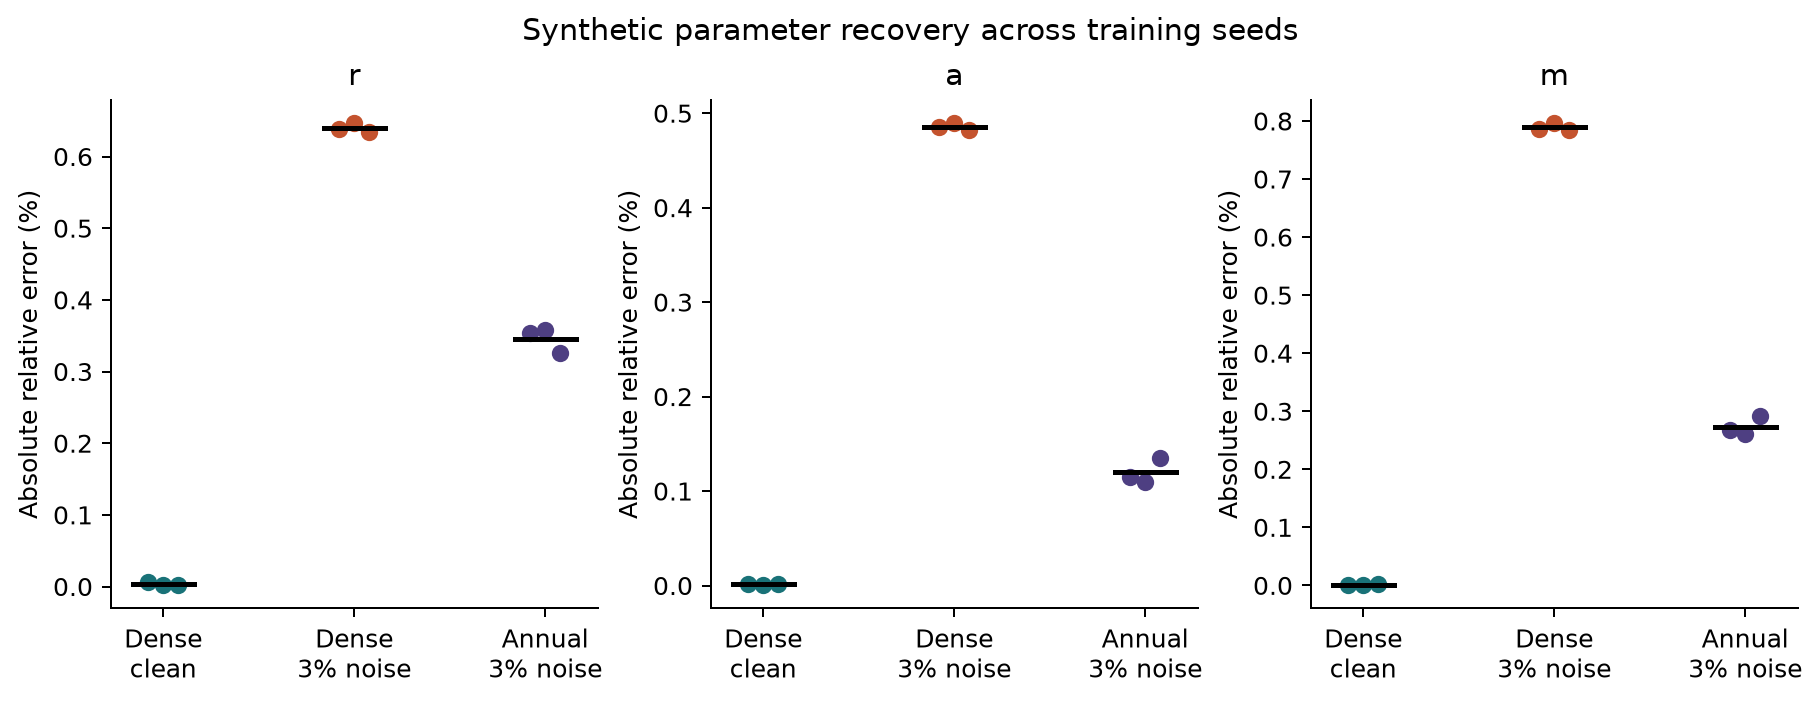

In [11]:
def table(path, columns=None):
    with Path(path).open(newline='', encoding='utf-8') as f:
        rows = list(csv.DictReader(f))
    columns = columns or list(rows[0])
    body = '| ' + ' | '.join(columns) + ' |\n| ' + ' | '.join(['---'] * len(columns)) + ' |\n'
    for row in rows:
        values = []
        for name in columns:
            value = row[name]
            try:
                value = f'{float(value):.6g}'
            except ValueError:
                pass
            values.append(value)
        body += '| ' + ' | '.join(values) + ' |\n'
    display(Markdown(body))
table(OUT / 'parameter_recovery.csv', ['case','seed','variant','parameter','estimated','truth','learned','absolute_relative_error_percent'])
display(Image(filename=str(OUT / 'figures/parameter_recovery.png')))

## Loss curves and mechanistic consistency

The curves show the weighted total and unweighted loss components. Adam steps are
followed by L-BFGS closure evaluations, which include line-search trials. The warmup
is omitted from this trace. Low loss is not by itself proof of convergence. Compare
the network with the ODE using its learned parameters, then inspect residuals on an
offset grid inside the training interval.

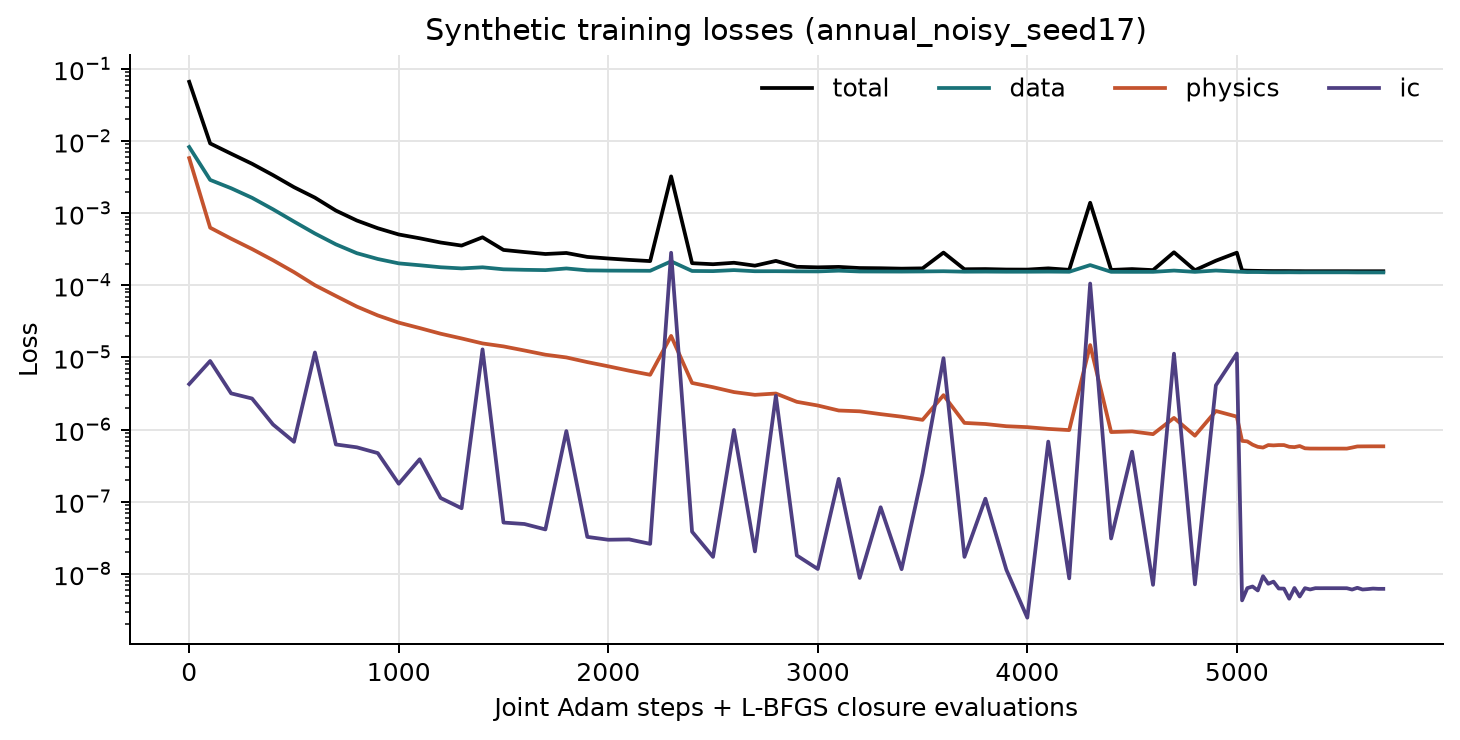

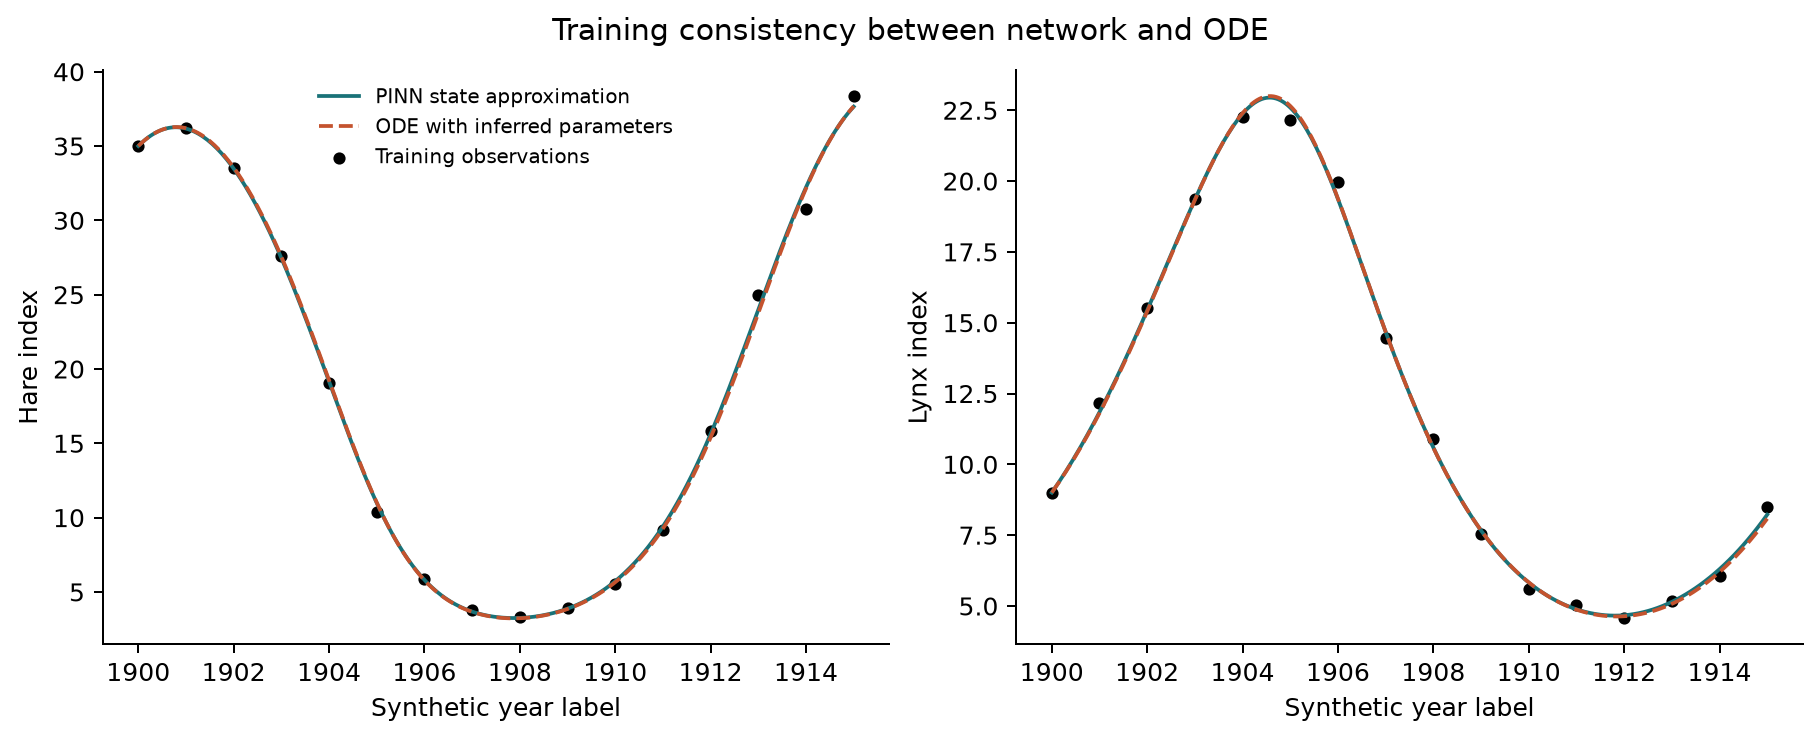

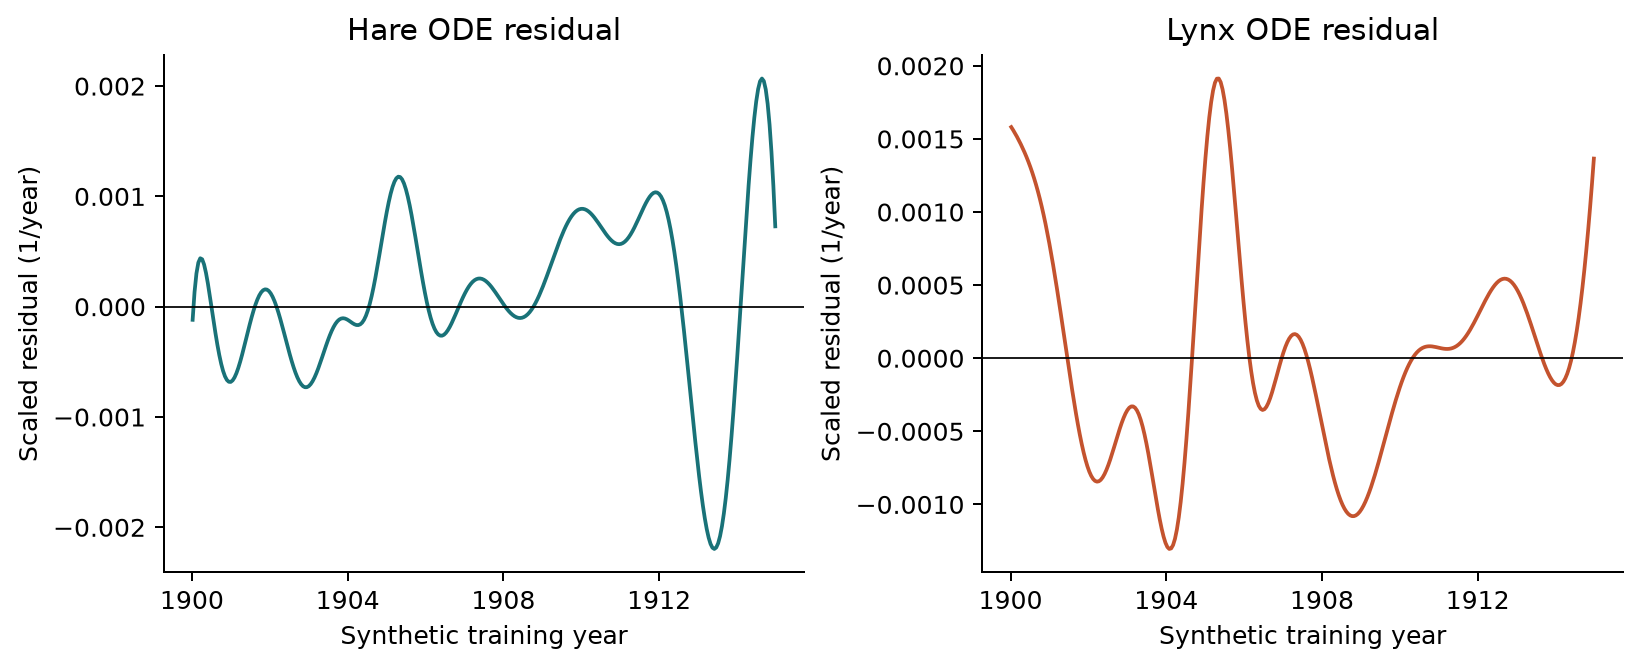

Training objective: 0.00015716051500995552
Adam stopping reason: maximum_steps
L-BFGS iterations / evaluations: 600 699
Independent residual RMS: [0.0007874312996601093, 0.000738492895174211]


In [12]:
for name in ('training_losses', 'network_ode_consistency', 'residual_check'):
    display(Image(filename=str(OUT / 'figures' / f'{name}.png')))
selected = json.loads((OUT / 'selected_run.json').read_text())
audit = json.loads((OUT / 'runs' / selected['run_id'] / 'summary.json').read_text())
print('Training objective:', audit['audit']['training_objective'])
print('Adam stopping reason:', audit['audit']['adam_stop'])
print('L-BFGS iterations / evaluations:', audit['audit']['lbfgs_iterations'], audit['audit']['lbfgs_closure_evaluations'])
print('Independent residual RMS:', audit['residual_check_rms'])

## Frozen ODE forecasts and matching baseline

All forecasts integrate from the same first training observation. The PINN network is
not extrapolated past 1915. The baseline fits the same three unknowns and fixed values
with six starts and the same scaling, initial state, bounds and RK45 settings.

RMSE and MAE are separate for hare and lynx. Noisy-observation scores answer a different
question from latent-truth scores. The selected default annual seed minimizes its
training objective; every default seed's held-out score remains visible.

| method | run_id | target | selected | hare_rmse | lynx_rmse | hare_mae | lynx_mae |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PINN-derived ODE | annual_noisy_seed17 | noisy_observations | True | 0.331892 | 0.386242 | 0.27799 | 0.246304 |
| PINN-derived ODE | annual_noisy_seed17 | latent_truth | True | 0.0523703 | 0.0820165 | 0.0474548 | 0.0712607 |
| PINN-derived ODE | annual_noisy_seed29 | noisy_observations | False | 0.328435 | 0.387091 | 0.272232 | 0.246939 |
| PINN-derived ODE | annual_noisy_seed29 | latent_truth | False | 0.0493519 | 0.0834565 | 0.0448497 | 0.0735813 |
| PINN-derived ODE | annual_noisy_seed43 | noisy_observations | False | 0.34741 | 0.38347 | 0.301903 | 0.24391 |
| PINN-derived ODE | annual_noisy_seed43 | latent_truth | False | 0.0709578 | 0.075731 | 0.0665458 | 0.0600995 |
| least_squares | least_squares | noisy_observations | True | 0.296172 | 0.441202 | 0.250988 | 0.303519 |
| least_squares | least_squares | latent_truth | True | 0.223648 | 0.157028 | 0.190988 | 0.148613 |


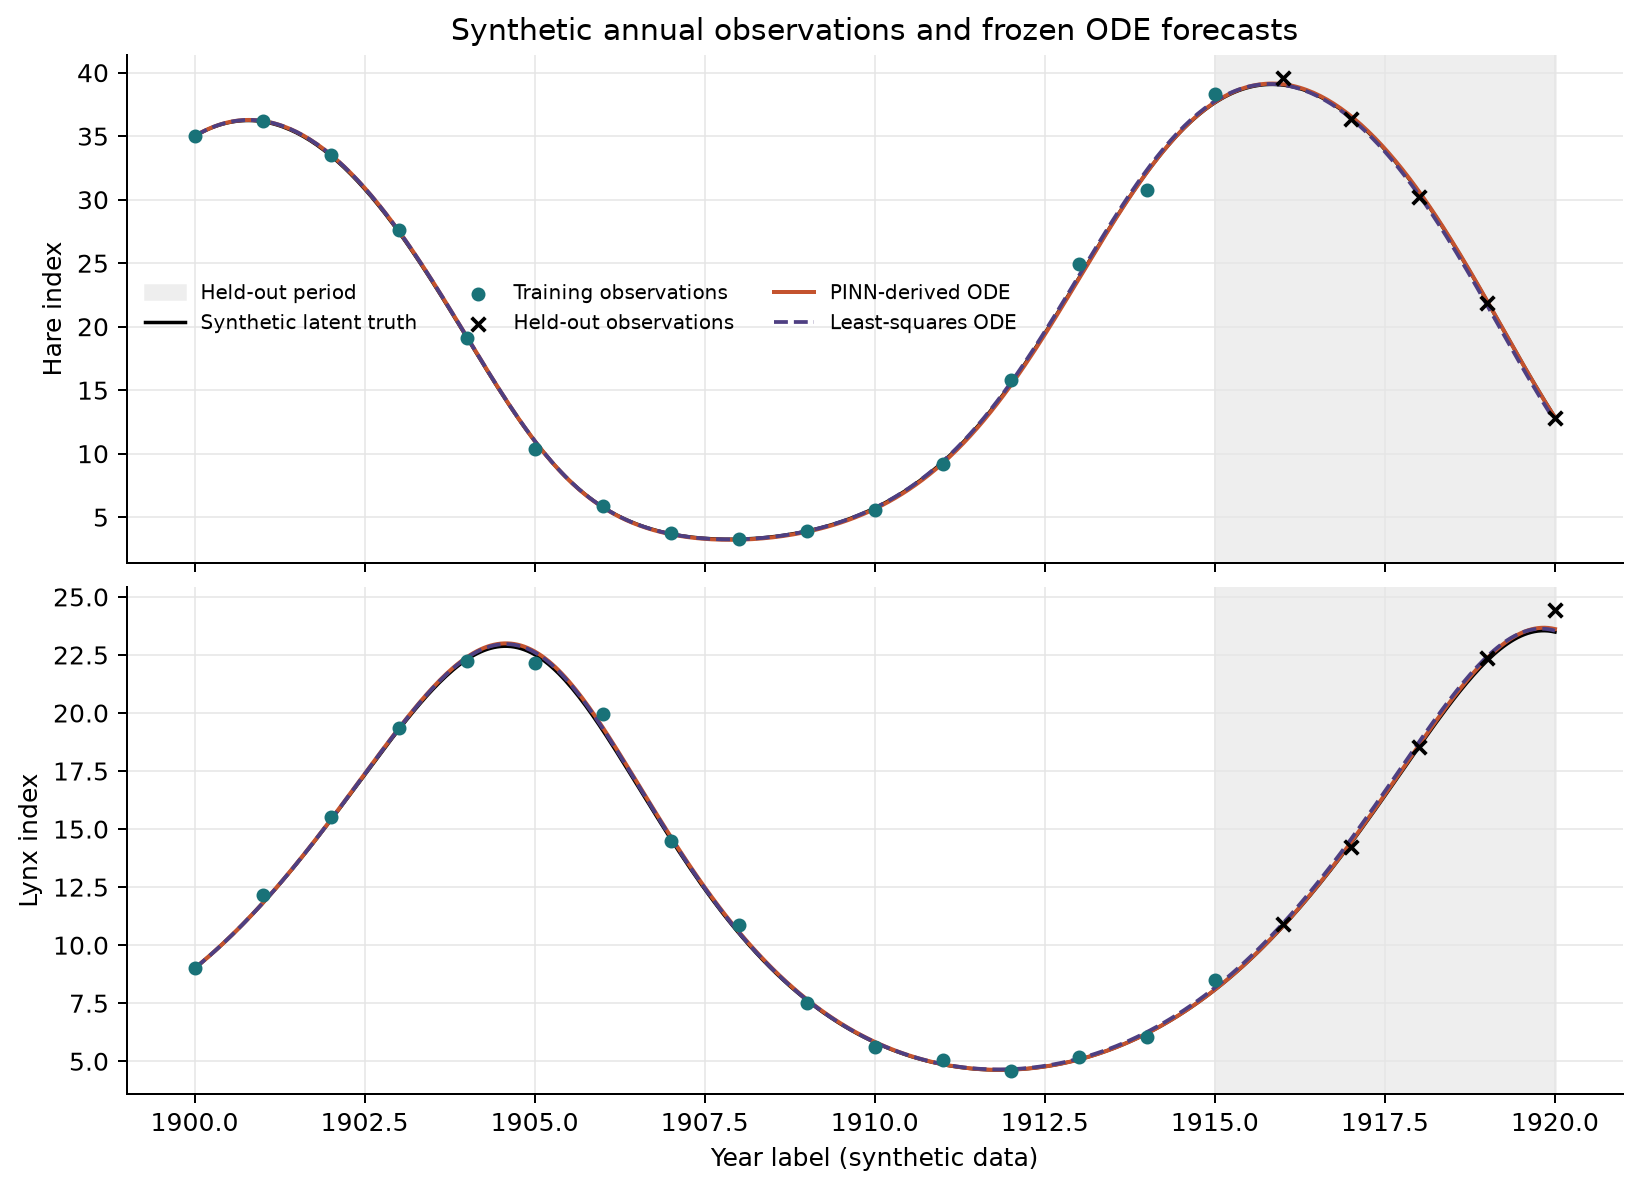

Handoff forecast (synthetic units):
Year,Hare,Lynx
1916.0,39.092319954637176,10.821878245476157
1917.0,36.580811787773214,14.427779584464009
1918.0,30.649941535236188,18.610374394038477
1919.0,22.05172475934246,22.350366437092276
1920.0,12.853444560906127,23.614523348012604



In [13]:
table(OUT / 'heldout_metrics.csv')
display(Image(filename=str(OUT / 'figures/forecast_comparison.png')))
print('Handoff forecast (synthetic units):')
print((OUT / 'predictions_for_advay.csv').read_text())

## Loss weights, initial guesses and local identifiability

Sensitivity variants fix optimizer seed 17 and change physics weight from 10 to 1 or
100, or multiply the unknown initial guesses by 0.6 or 1.4. These configurations were
prespecified and are not a test-based search.

The singular values of the scaled trajectory Jacobian with respect to log parameters
compare the primary three-parameter local problem with locally varying all six
parameters. This is not an all-six PINN fit or a proof of structural identifiability.

{
  "three_parameters": {
    "names": [
      "r",
      "a",
      "m"
    ],
    "singular_values": [
      8.767111355892308,
      3.0382232406003626,
      2.3419881708490546
    ],
    "condition_number": 3.743448180062291
  },
  "six_parameters": {
    "names": [
      "r",
      "K",
      "a",
      "b",
      "e",
      "m"
    ],
    "singular_values": [
      11.036435291935716,
      3.913353646841963,
      2.895735306400249,
      1.687924242164453,
      0.3100081075832236,
      0.1831946949285972
    ],
    "condition_number": 60.244295263229795
  },
  "interpretation": "Local finite-difference diagnostic at learned parameters, not a proof of global or structural identifiability"
}



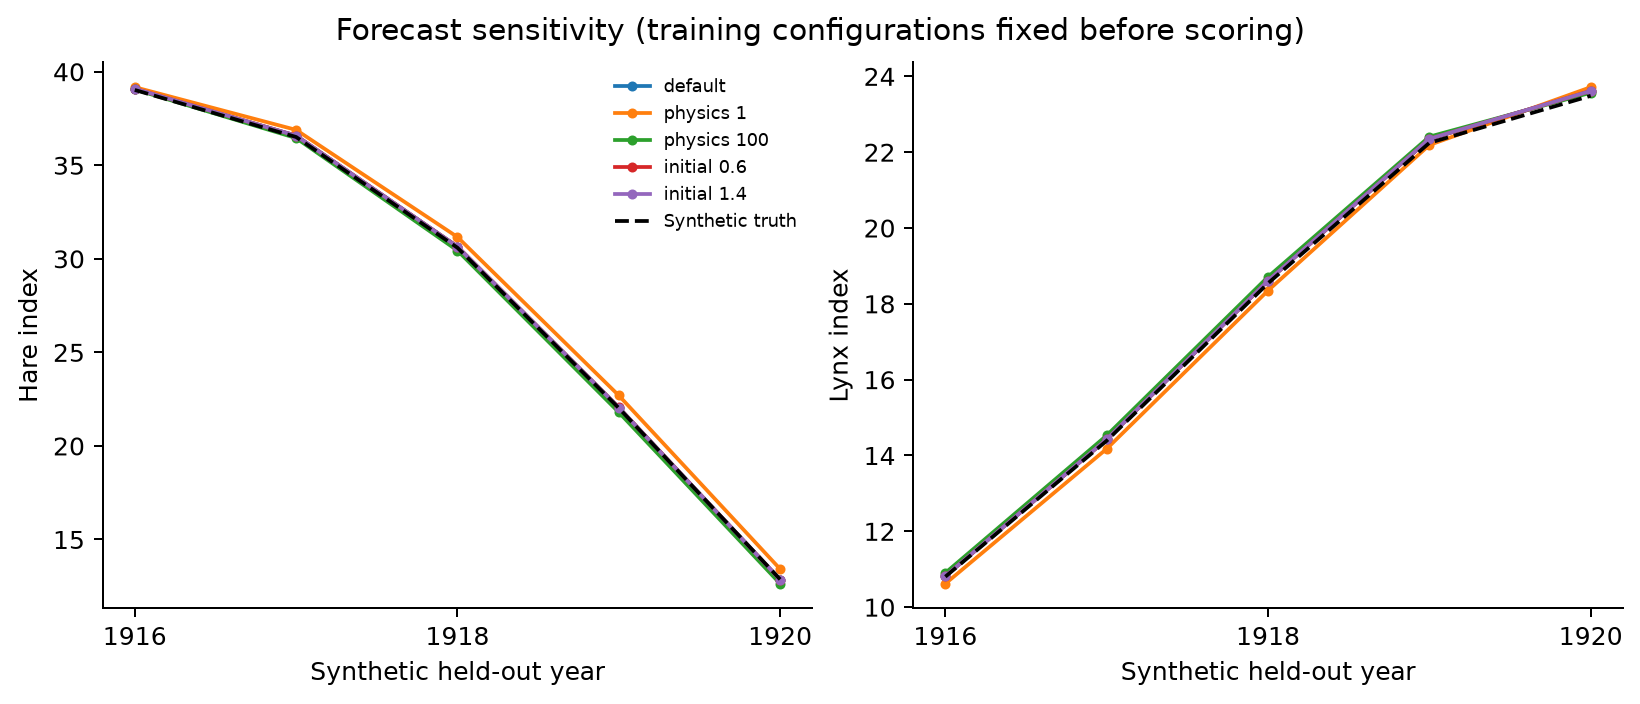

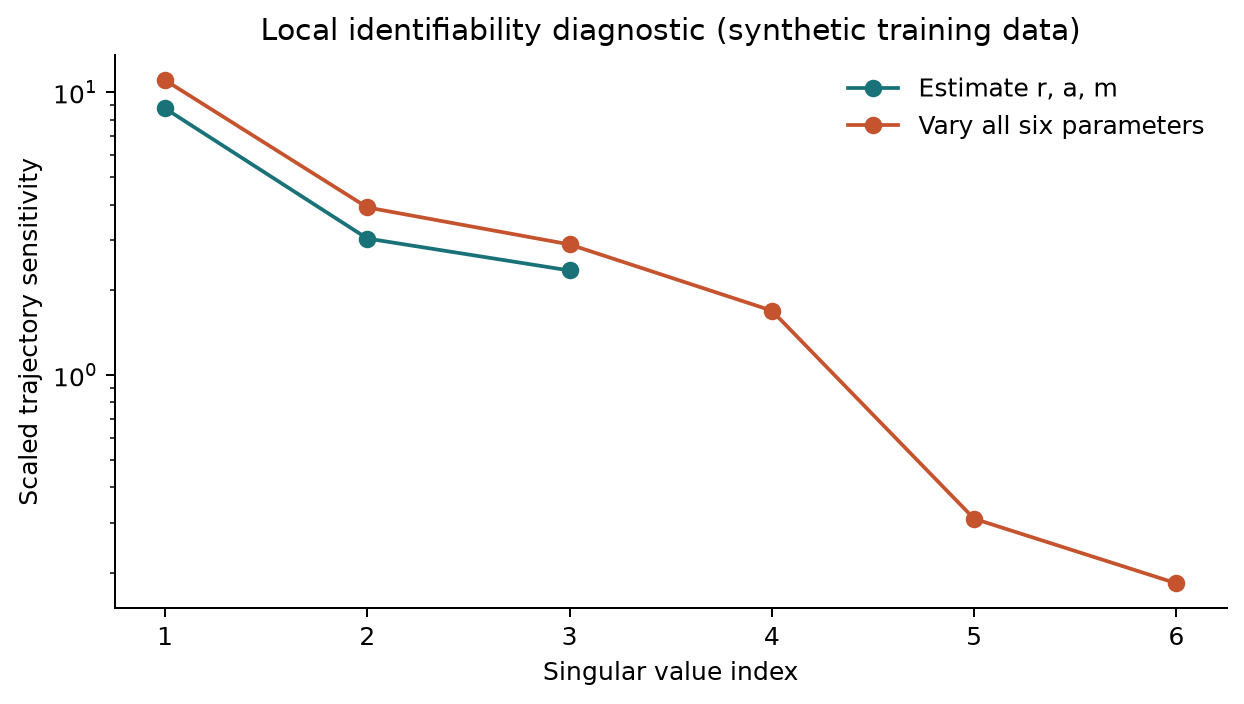

In [14]:
print((OUT / 'identifiability.json').read_text())
for name in ('sensitivity', 'identifiability'):
    display(Image(filename=str(OUT / 'figures' / f'{name}.png')))

## Findings and limits

The following summary is generated from the saved experiment outputs. It distinguishes
measured results from assumptions, mixed comparisons and work still needed for real
observations. The complete method and team integration instructions are in `docs/`.

In [15]:
display(Markdown((ROOT / 'docs/results_summary.md').read_text()))

# Measured synthetic results

The complete reference run contains **13 PINN fits** on one CPU thread.
Training took 213.7 seconds in total, excluding imports, baseline fitting,
plotting and notebook execution. The exact runtime versions and source hashes are in
`results/synthetic/manifest.json`. These are synthetic index trajectories, not historical data.

## Parameter recovery

All primary fits estimate r, a and m; K=60, b=20 and e=0.6 are fixed correctly for this
controlled experiment. Maximum absolute relative errors across the three default seeds
and the three estimated parameters were:

| Training observations | Maximum error |
|---|---:|
| 61 clean quarterly observations | 0.0057% |
| 61 quarterly observations with 3% noise | 0.796% |
| 16 annual observations with 3% noise | 0.358% |

This comparison holds the noise seed fixed within each case. It does not show that
annual observations are generally more informative than quarterly observations; the
finite noise realizations differ and the three rates are conditionally identifiable.

The selected default annual run is **annual_noisy_seed17**, chosen using the smallest
weighted training objective. Its estimates are r=1.00353118, a=1.99769981 and
m=0.49866347. All seeds and sensitivity variants are retained in `parameter_recovery.csv`.

## Held-out ODE forecasts

These scores use five years labelled 1916â€“1920. Parameters and the seed choice were
frozen before scoring. The ODE is integrated from 1900 using the same initial state and
RK45 settings for both methods. Values are in arbitrary synthetic abundance-index units.

| Method | Evaluation target | Hare RMSE | Lynx RMSE | Hare MAE | Lynx MAE |
|---|---|---:|---:|---:|---:|
| PINN-derived ODE | noisy observations | 0.33189 | 0.38624 | 0.27799 | 0.24630 |
| PINN-derived ODE | latent truth | 0.05237 | 0.08202 | 0.04745 | 0.07126 |
| least_squares | noisy observations | 0.29617 | 0.44120 | 0.25099 | 0.30352 |
| least_squares | latent truth | 0.22365 | 0.15703 | 0.19099 | 0.14861 |

Against noisy observations, least squares has the lower hare error and the selected
PINN-derived ODE has the lower lynx error. Against latent truth the selected PINN-derived
ODE is closer for both species in this realization. This mixed result is not evidence
of general superiority. The experiment favors the mechanistic model because the same
equations generated the observations, three constants are known, and the initial state
is exact. No claim about historical predictive accuracy follows.

## Sensitivity and identifiability

The prespecified physics weights 1 and 100 and initial-guess factors 0.6 and 1.4 produce
the trajectories in `figures/sensitivity.png`. This is a diagnostic sweep, not a test-based
search for the best configuration. The local sensitivity condition number rises from
3.74 when varying r,a,m to
60.24 when all six parameters are varied
locally. That indicates more weakly constrained directions in the larger local problem;
it does not prove structural non-identifiability or establish six-parameter recovery.

The independent residual grid and network/ODE consistency figures check two failure
modes: satisfying physics only at the training grid and fitting observations with a
network whose inferred ODE follows a different trajectory. Neither diagnostic is a
formal error bound or a substitute for held-out validation.

## Practical limits

Three optimizer seeds on one noise draw do not quantify observation uncertainty. Bounds,
loss weights and fixed constants are provisional. The forecast contains only five test
points per species. The synthetic system omits ecology and the pelt-trading observation
mechanism. Real fitting requires the team's frozen equations, units, feasibility ranges,
data provenance and evaluation protocol. See `docs/team_handoff.md`.


## Handoff and acknowledgement

Send Advay `predictions_for_advay.csv`, `selected_run.json`, the seed-wise metrics and
training logs. Confirm equations/scaling with Arnav, parameter constraints with Joel,
and the solver contract with Rishi. Real fitting must use new outputs and replace the
synthetic results and provenance. The present package does not invent teammate work.

The report source is `report/yash_pinn_section.tex`, with generated tables and EPS figures.
Presentation notes are in `presentation/yash_pinn_notes.md`. The AI assistance log records
assistant-generated work and automated checks; Yash should add his own manual checks.

References: [Rosenzweig–MacArthur (1963)](https://doi.org/10.1086/282272),
[Raissi et al. (2019)](https://doi.org/10.1016/j.jcp.2018.10.045),
[PyTorch autograd](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad.html),
[SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).